<a href="https://colab.research.google.com/github/septiananugrah-ship-it/Template-Dokumen/blob/main/grafik_photoelektrik_kel_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

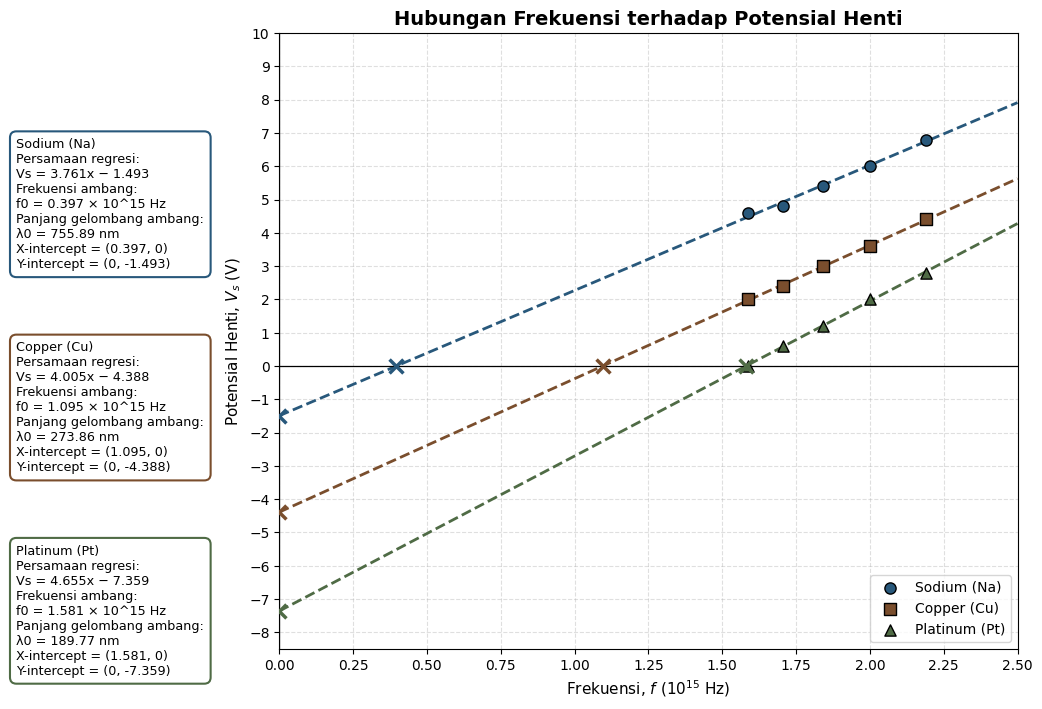

HASIL REGRESI LINEAR

Sodium (Na)
Persamaan: Vs = 3.7614x + (-1.4928)
Gradien   = 3.761390 V per 10^15 Hz
Intersep  = -1.4928 V
f0        = 3.9688e+14 Hz
lambda0   = 755.89 nm

Copper (Cu)
Persamaan: Vs = 4.0054x + (-4.3877)
Gradien   = 4.005369 V per 10^15 Hz
Intersep  = -4.3877 V
f0        = 1.0955e+15 Hz
lambda0   = 273.86 nm

Platinum (Pt)
Persamaan: Vs = 4.6552x + (-7.3592)
Gradien   = 4.655156 V per 10^15 Hz
Intersep  = -7.3592 V
f0        = 1.5809e+15 Hz
lambda0   = 189.77 nm


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# DATA PRAKTIKUM
data = {
    "Sodium (Na)": {
        "lambda": [137, 150, 163, 176, 189],
        "Vs": [6.80, 6.00, 5.40, 4.80, 4.60],
        "warna": "#28587B",
        "marker": "o"
    },
    "Copper (Cu)": {
        "lambda": [137, 150, 163, 176, 189],
        "Vs": [4.40, 3.60, 3.00, 2.40, 2.00],
        "warna": "#7A4E2D",
        "marker": "s"
    },
    "Platinum (Pt)": {
        "lambda": [137, 150, 163, 176, 189],
        "Vs": [2.80, 2.00, 1.20, 0.60, 0.00],
        "warna": "#4F6B45",
        "marker": "^"
    }
}

c = 3.00e8  # kecepatan cahaya (m/s)

fig, (ax_info, ax) = plt.subplots(
    1, 2, figsize=(13, 8),
    gridspec_kw={"width_ratios": [1.15, 4], "wspace": 0.12}
)

hasil = {}

# PERHITUNGAN DAN GRAFIK
for bahan, d in data.items():
    lam = np.array(d["lambda"]) * 1e-9
    Vs = np.array(d["Vs"])
    f = c / lam
    x = f / 1e15  # frekuensi dalam satuan 10^15 Hz

    # Regresi: Vs = m*x + b
    m, b = np.polyfit(x, Vs, 1)
    f0 = (-b / m) * 1e15
    lambda0 = c / f0

    hasil[bahan] = (m, b, f0, lambda0)

    # Titik eksperimen
    ax.scatter(
        x, Vs, s=65, marker=d["marker"],
        color=d["warna"], edgecolor="black",
        label=bahan, zorder=5
    )

    # Garis regresi
    xline = np.linspace(0, 2.5, 300)
    ax.plot(
        xline, m*xline + b,
        "--", color=d["warna"], linewidth=2
    )

    # Tanda intersep
    ax.scatter(
        -b/m, 0, marker="x", s=100,
        color=d["warna"], linewidth=2.5, zorder=7
    )
    ax.scatter(
        0, b, marker="x", s=100,
        color=d["warna"], linewidth=2.5, zorder=7
    )

# FORMAT GRAFIK
ax.set_title(
    "Hubungan Frekuensi terhadap Potensial Henti",
    fontsize=14, fontweight="bold"
)
ax.set_xlabel(r"Frekuensi, $f$ ($10^{15}$ Hz)", fontsize=11)
ax.set_ylabel(r"Potensial Henti, $V_s$ (V)", fontsize=11)
ax.set_xlim(0, 2.5)
ax.set_ylim(-8.5, 10)
ax.set_xticks(np.arange(0, 2.51, 0.25))
ax.set_yticks(np.arange(-8, 10.1, 1))
ax.grid(True, linestyle="--", alpha=0.4)
ax.axhline(0, color="black", linewidth=0.9)
ax.axvline(0, color="black", linewidth=0.9)
ax.legend(loc="lower right", frameon=True)

# KOTAK INFORMASI REGRESI
ax_info.axis("off")
posisi = [0.83, 0.50, 0.17]

for i, (bahan, nilai) in enumerate(hasil.items()):
    m, b, f0, lambda0 = nilai
    warna = data[bahan]["warna"]

    tanda = "+" if b >= 0 else "−"
    persamaan = f"Vs = {m:.3f}x {tanda} {abs(b):.3f}"

    teks = (
        f"{bahan}\n"
        f"Persamaan regresi:\n"
        f"{persamaan}\n"
        f"Frekuensi ambang:\n"
        f"f0 = {f0/1e15:.3f} × 10^15 Hz\n"
        f"Panjang gelombang ambang:\n"
        f"λ0 = {lambda0*1e9:.2f} nm\n"
        f"X-intercept = ({-b/m:.3f}, 0)\n"
        f"Y-intercept = (0, {b:.3f})"
    )

    ax_info.text(
        0.03, posisi[i], teks,
        transform=ax_info.transAxes,
        fontsize=9.2, va="top",
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="white",
            edgecolor=warna,
            linewidth=1.5
        )
    )

plt.savefig(
    "grafik_fotolistrik_final.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# HASIL PERHITUNGAN
print("HASIL REGRESI LINEAR")
print("=" * 55)

for bahan, (m, b, f0, lambda0) in hasil.items():
    print(f"\n{bahan}")
    print(f"Persamaan: Vs = {m:.4f}x + ({b:.4f})")
    print(f"Gradien   = {m:.6f} V per 10^15 Hz")
    print(f"Intersep  = {b:.4f} V")
    print(f"f0        = {f0:.4e} Hz")
    print(f"lambda0   = {lambda0*1e9:.2f} nm")

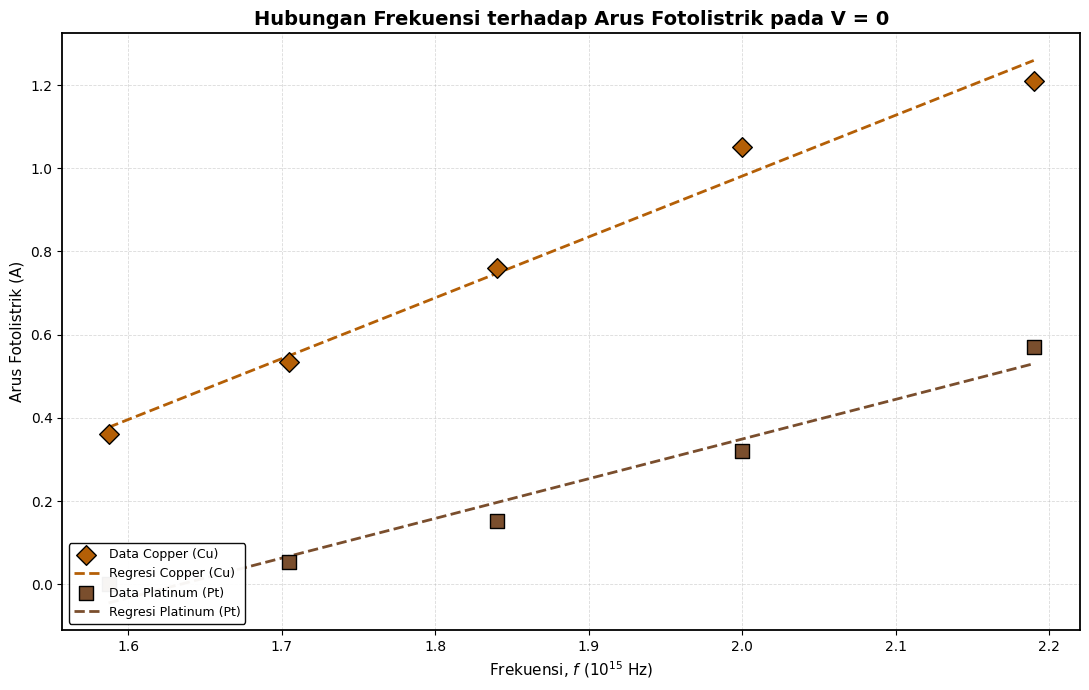

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# DATA EKSPERIMEN EFEK FOTOLISTRIK
# V = 0
# =========================================================
data = {
    "Copper (Cu)": {
        "lambda": [137, 150, 163, 176, 189],
        "I": [1.209, 1.052, 0.759, 0.533, 0.361]
    },

    "Platinum (Pt)": {
        "lambda": [137, 150, 163, 176, 189],
        "I": [0.571, 0.320, 0.153, 0.054, 0.000]
    }
}

# =========================================================
# KONSTANTA, WARNA, DAN MARKER
# =========================================================
c = 3.00e8  # m/s

warna = {
    "Copper (Cu)": "#B45F06",
    "Platinum (Pt)": "#7A4E2D"
}

marker = {
    "Copper (Cu)": "D",
    "Platinum (Pt)": "s"
}

# =========================================================
# FIGURE
# =========================================================
fig, ax = plt.subplots(figsize=(11, 7))

# Menampung hasil regresi
hasil_regresi = {}

# =========================================================
# PLOT DATA DAN REGRESI LINEAR
# =========================================================
for bahan, nilai in data.items():

    # Konversi panjang gelombang nm ke m
    lam = np.array(nilai["lambda"], dtype=float) * 1e-9

    # Arus fotolistrik
    I = np.array(nilai["I"], dtype=float)

    # Frekuensi dalam satuan 10^15 Hz
    f = c / lam
    x = f / 1e15

    # Titik data eksperimen
    ax.scatter(
        x, I,
        s=100,
        marker=marker[bahan],
        color=warna[bahan],
        edgecolor="black",
        linewidth=1,
        label=f"Data {bahan}",
        zorder=5
    )

    # Regresi linear: I = m*x + b
    m, b = np.polyfit(x, I, 1)

    # Prediksi dan R kuadrat
    I_pred = m * x + b
    ss_res = np.sum((I - I_pred)**2)
    ss_tot = np.sum((I - np.mean(I))**2)
    r2 = 1 - ss_res / ss_tot

    hasil_regresi[bahan] = (m, b, r2)

    # Garis regresi
    x_line = np.linspace(min(x), max(x), 300)
    y_line = m * x_line + b

    ax.plot(
        x_line, y_line,
        color=warna[bahan],
        linestyle="--",
        linewidth=2,
        label=f"Regresi {bahan}"
    )


# =========================================================
# LABEL DAN TAMPILAN
# =========================================================
ax.set_title(
    "Hubungan Frekuensi terhadap Arus Fotolistrik pada V = 0",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel(
    r"Frekuensi, $f$ ($10^{15}$ Hz)",
    fontsize=11
)

ax.set_ylabel(
    "Arus Fotolistrik (A)",
    fontsize=11
)

ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.45)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.3)

ax.legend(
    loc="lower left",
    frameon=True,
    framealpha=0.95,
    edgecolor="black",
    fontsize=9
)

plt.tight_layout()

# Simpan grafik
plt.savefig(
    "grafik_frekuensi_vs_arus.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



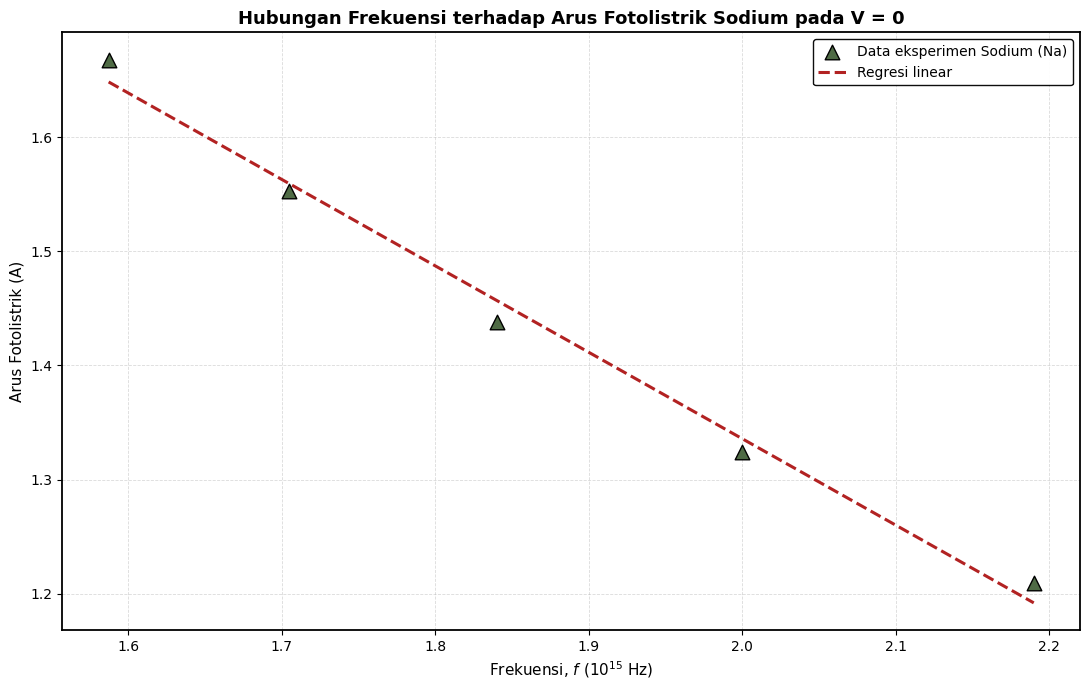

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# DATA EKSPERIMEN EFEK FOTOLISTRIK SODIUM
# V = 0
# =========================================================
lamda = np.array([137, 150, 163, 176, 189], dtype=float)
I = np.array([1.209, 1.324, 1.438, 1.553, 1.668])

# =========================================================
# KONSTANTA DAN FREKUENSI
# =========================================================
c = 3.00e8
lamda_m = lamda * 1e-9
f = c / lamda_m
f_scaled = f / 1e15  # Satuan 10^15 Hz

# =========================================================
# REGRESI LINEAR
# =========================================================
m, b = np.polyfit(f_scaled, I, 1)

I_pred = m * f_scaled + b

ss_res = np.sum((I - I_pred)**2)
ss_tot = np.sum((I - np.mean(I))**2)
r2 = 1 - ss_res / ss_tot

# Garis regresi
f_line = np.linspace(min(f_scaled), max(f_scaled), 300)
I_line = m * f_line + b

# =========================================================
# GRAFIK
# =========================================================
plt.figure(figsize=(11, 7))

# Titik data asli: simbol segitiga
plt.scatter(
    f_scaled,
    I,
    s=110,
    marker="^",
    color="#4F6B45",
    edgecolor="black",
    linewidth=1.0,
    label="Data eksperimen Sodium (Na)",
    zorder=5
)

# Garis regresi linear
plt.plot(
    f_line,
    I_line,
    color="#B22222",
    linestyle="--",
    linewidth=2.2,
    label="Regresi linear"
)

# =========================================================
# LABEL DAN JUDUL
# =========================================================
plt.title(
    "Hubungan Frekuensi terhadap Arus Fotolistrik Sodium pada V = 0",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel(
    r"Frekuensi, $f$ ($10^{15}$ Hz)",
    fontsize=11
)

plt.ylabel(
    "Arus Fotolistrik (A)",
    fontsize=11
)

# =========================================================
# GRID DAN BORDER
# =========================================================
plt.grid(True, linestyle="--", linewidth=0.6, alpha=0.45)

ax = plt.gca()

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.3)

plt.legend(
    loc="best",
    frameon=True,
    framealpha=0.95,
    edgecolor="black"
)

plt.tight_layout()

# =========================================================
# SIMPAN GRAFIK
# =========================================================
plt.savefig(
    "grafik_frekuensi_vs_arus_sodium.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()